# 07 · Tiempos de espera entre eventos

El algoritmo de Gillespie genera tiempos de espera exponenciales mientras el estado y el ambiente permanezcan constantes. Compararemos las esperas observadas con la escala teórica 1/a₀ de cada estado.

> **ProteinMotorSim 0.1.1** · Ejemplo educativo. Las tasas predeterminadas del modelo son ilustrativas y no representan todavía una parametrización experimental validada.

## Preparación del entorno

Esta celda localiza automáticamente la raíz del repositorio e incorpora `src/` a la ruta de importación. Instala antes las dependencias con `python -m pip install -e ".[dev,viz]"` y selecciona el kernel `Python (ProteinMotorSim)`.

In [1]:
from pathlib import Path
import sys

# Busca la raíz del proyecto desde el directorio actual o sus carpetas padre.
_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in _candidates if (path / "pyproject.toml").exists() and (path / "src").is_dir()),
    None,
)

if PROJECT_ROOT is None:
    raise RuntimeError(
        "No se encontró ProteinMotorSim. Abre JupyterLab desde la carpeta raíz "
        "del proyecto o desde su carpeta notebooks/."
    )

sys.path.insert(0, str(PROJECT_ROOT / "src"))
print(f"Proyecto detectado: {PROJECT_ROOT}")

Proyecto detectado: /home/zix/ProteinMotorSim


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from protein_motor_sim import Environment, GillespieSimulator, Kinesin1

motor = Kinesin1()
environment = Environment(atp_concentration=1.0e-3, temperature_K=310.0)
network = motor.build_network()
trajectory = GillespieSimulator().run(
    motor, environment, t_max=0.5, seed=31415,
)

## 1. Extraer intervalos entre eventos reales

In [3]:
waiting_by_state = {}
for i in range(1, len(trajectory.times_s)):
    event = trajectory.events[i]
    if event == "observation_end":
        continue  # No es un evento cinético: es el final de la ventana.
    source_state = trajectory.states[i - 1]
    waiting_time = trajectory.times_s[i] - trajectory.times_s[i - 1]
    waiting_by_state.setdefault(source_state, []).append(waiting_time)

for state_name, waits in waiting_by_state.items():
    rates = [rate for _, rate in network.rates(state_name, environment)]
    total_rate = sum(rates)
    theoretical_mean = 1.0 / total_rate if total_rate > 0 else float("inf")
    print(
        f"{state_name:20s}: n={len(waits):3d}, "
        f"media observada={np.mean(waits):.5g} s, "
        f"media teórica={theoretical_mean:.5g} s"
    )

bound_apo           : n= 26, media observada=0.001152 s, media teórica=0.0009998 s
atp_bound           : n= 25, media observada=0.010661 s, media teórica=0.012469 s
post_hydrolysis     : n= 25, media observada=0.0061774 s, media teórica=0.0099751 s


## 2. Histograma de esperas en un estado elegido

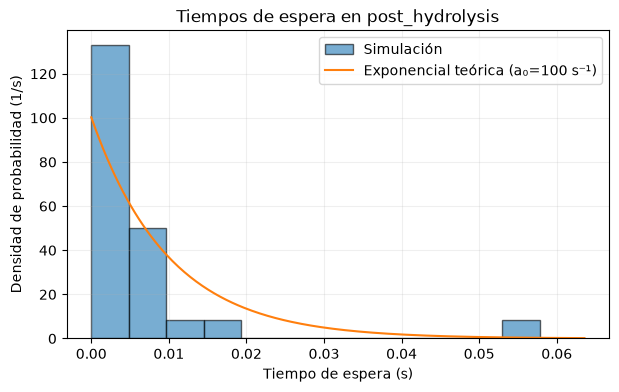

In [4]:
state_to_plot = "post_hydrolysis"
waits = waiting_by_state.get(state_to_plot, [])
if waits:
    total_rate = sum(rate for _, rate in network.rates(state_to_plot, environment))
    upper = max(waits) * 1.1
    x = np.linspace(0, upper, 250)
    density = total_rate * np.exp(-total_rate * x)

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(waits, bins=12, density=True, alpha=0.6, edgecolor="black", label="Simulación")
    ax.plot(x, density, label=f"Exponencial teórica (a₀={total_rate:.3g} s⁻¹)")
    ax.set_xlabel("Tiempo de espera (s)")
    ax.set_ylabel("Densidad de probabilidad (1/s)")
    ax.set_title(f"Tiempos de espera en {state_to_plot}")
    ax.legend()
    ax.grid(alpha=0.2)
    plt.show()
else:
    print(f"No se observaron visitas a {state_to_plot!r}; prueba otra semilla o aumenta t_max.")

**Interpretación:** la distribución exponencial se aplica al tiempo hasta cualquier transición saliente, con parámetro igual a la suma de las tasas positivas disponibles en el estado. Una muestra corta puede diferir considerablemente de la curva teórica.